In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/spotify-2023-cleaned.csv", encoding="latin-1")

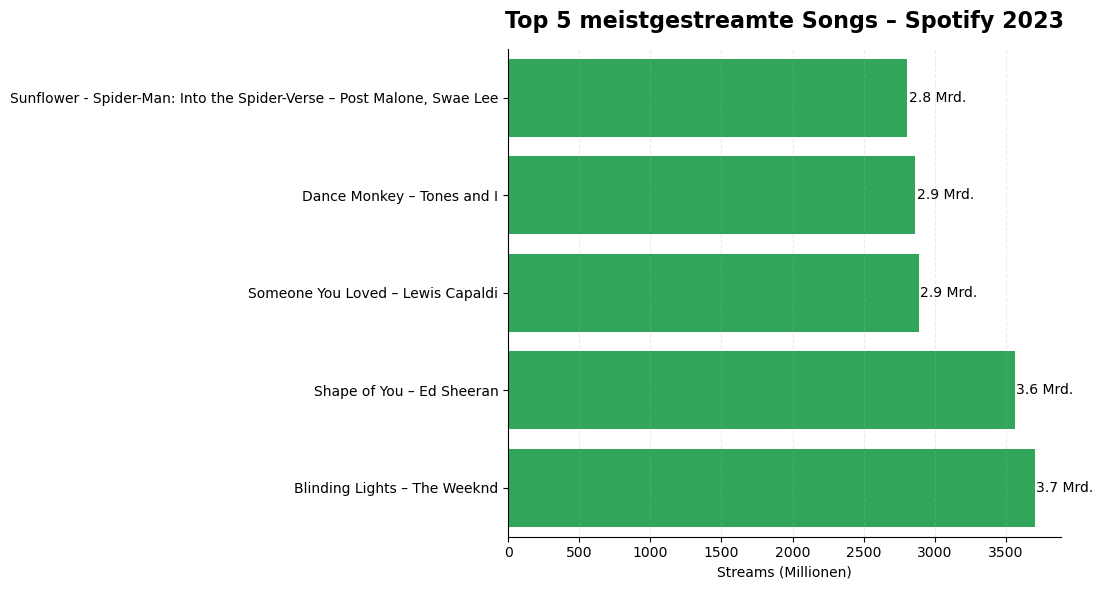

In [9]:
top_5_streams = (
    df[["track_name", "artist(s)_name", "streams"]]
    .assign(streams=lambda d: pd.to_numeric(d["streams"], errors="coerce"))
    .sort_values("streams", ascending=False)
    .head(5)
    .copy()
)

top_5_streams["label"] = (
    top_5_streams["track_name"] + " – " +
    top_5_streams["artist(s)_name"]
)

top_5_streams["streams_mio"] = top_5_streams["streams"] / 1_000_000

top_5_streams = top_5_streams.sort_values("streams_mio")

def format_streams(value):
    if value >= 1_000_000_000:
        return f"{value / 1_000_000_000:.1f} Mrd."
    return f"{value / 1_000_000:.0f} Mio."

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=top_5_streams,
    x="streams_mio",
    y="label",
    color="#1DB954"
)

plt.title(
    "Top 5 meistgestreamte Songs – Spotify 2023",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Streams (Millionen)")
plt.ylabel("")

for i, row in top_5_streams.reset_index(drop=True).iterrows():
    ax.text(
        row["streams_mio"] + 10,
        i,
        format_streams(row["streams"]),
        va="center",
        fontsize=10
    )

plt.grid(axis="x", linestyle="--", alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
top5_keys = df["key"].value_counts().head(5)

plt.figure(figsize=(8, 5))
sns.barplot(x=top5_keys.index, y=top5_keys.values, hue=top5_keys.index, palette="viridis")
plt.title("Top 5 Keys - Spotify 2023")
plt.xlabel("Key")
plt.ylabel("Anzahl Songs")
plt.show()

In [ ]:
top_5_keys = df["key"].value_counts().head(5)

key_mode_counts = (
    df[df["key"].isin(top_5_keys.index)]
    .groupby(["key", "mode"])
    .size()
    .unstack(fill_value=0)
)

key_mode_counts = key_mode_counts.loc[top_5_keys.index]

ax = key_mode_counts.plot(
    kind="bar",
    stacked=False,
    figsize=(9, 5)
)

ax.set_title("Major- und Minor-Verteilung der Top 5 Keys")
ax.set_xlabel("Key")
ax.set_ylabel("Anzahl der Songs")

plt.xticks(rotation=0)
plt.legend(title="Mode")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

bpm = df["bpm"].dropna()

counts, bins = np.histogram(bpm, bins=30)

top_5 = np.argsort(counts)[-5:]

colors = ["#1DB954"] * len(counts)

for i in top_5:
    colors[i] = "#0B5D2A"

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    bins[:-1],
    counts,
    width=np.diff(bins),
    align="edge",
    color=colors
)

ax.set_title("BPM-Verteilung – Spotify 2023")
ax.set_xlabel("BPM")
ax.set_ylabel("Anzahl Songs")

total = counts.sum()
top_5_sorted = sorted(top_5, key=lambda i: counts[i], reverse=True)

# Infobox
info_text = "TOP 5 BPM-BEREICHE\n\n"

for rank, i in enumerate(top_5_sorted, start=1):
    percentage = counts[i] / total * 100

    info_text += (
        f"{rank}. {bins[i]:.0f}–{bins[i+1]:.0f} BPM\n"
        f"   {counts[i]} Songs ({percentage:.1f} %)\n"
    )

ax.text(
    1.02,
    0.95,
    info_text,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="white",
        edgecolor="#0B5D2A",
        linewidth=1.5
    )
)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

bpm = df["bpm"].dropna()

counts, bins = np.histogram(bpm, bins=30)

median_bpm = bpm.median()

# Balken bestimmen, in dem der Median liegt
median_bin = np.digitize(median_bpm, bins) - 1

# Farben
colors = ["#1DB954"] * len(counts)
colors[median_bin] = "#0B5D2A"

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    bins[:-1],
    counts,
    width=np.diff(bins),
    align="edge",
    color=colors
)

# Median-Infobox rechts oben
ax.text(
    0.98,
    0.95,
    f"MEDIAN\n{median_bpm:.0f} BPM",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#0B5D2A",
        linewidth=1.5
    )
)

ax.set_title("BPM-Verteilung – Spotify 2023")
ax.set_xlabel("BPM")
ax.set_ylabel("Anzahl der Songs")

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

median = df["danceability_%"].median()

ax = sns.histplot(
    df["danceability_%"],
    bins=20,
    kde=True,
    color="#1DB954",
    alpha=0.75,
    edgecolor="white",
    linewidth=0.7
)

# Median
plt.axvline(
    median,
    color="#0B5D2A",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median:.1f}%"
)

plt.title(
    "Danceability der meistgestreamten Songs 2023",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Danceability (%)", fontsize=11)
plt.ylabel("Anzahl Songs", fontsize=11)

plt.xlim(0, 100)

# Dezentes Grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

# Oberen und rechten Rahmen entfernen
sns.despine()

plt.legend(
    frameon=False,
    loc="upper left"
)

plt.tight_layout()
plt.show()